Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

Step 2: Load Dataset

In [2]:
df = pd.read_csv("/content/fake_job_postings.csv", on_bad_lines='skip', engine='python')

Step 3: View Dataset

In [3]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [4]:
df.shape

(1514, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1514 entries, 0 to 1513
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               1514 non-null   int64 
 1   title                1514 non-null   object
 2   location             1495 non-null   object
 3   department           501 non-null    object
 4   salary_range         241 non-null    object
 5   company_profile      1230 non-null   object
 6   description          1514 non-null   object
 7   requirements         1289 non-null   object
 8   benefits             897 non-null    object
 9   telecommuting        1514 non-null   int64 
 10  has_company_logo     1514 non-null   int64 
 11  has_questions        1514 non-null   int64 
 12  employment_type      1242 non-null   object
 13  required_experience  947 non-null    object
 14  required_education   930 non-null    object
 15  industry             1138 non-null   object
 16  functi

In [6]:
df.describe(include='all')

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
count,1514.000000,1514,1495,501,241,1230,1514,1289,897,1514.000000,1514.000000,1514.000000,1242,947,930,1138,990,1514.000000
unique,NaN,1188,697,219,167,495,1362,1092,683,NaN,NaN,NaN,5,7,12,89,35,NaN
top,NaN,English Teacher Abroad,"GB, LND, London",Sales,30000-40000,"Novitex Enterprise Solutions, formerly Pitney ...","Play with kids, get paid for it Love travel? J...",University degree required. TEFL / TESOL / CEL...,See job description,NaN,NaN,NaN,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology and Services,Information Technology,NaN
freq,NaN,71,65,51,11,121,73,85,113,NaN,NaN,NaN,977,302,494,129,136,NaN
mean,757.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.036328,0.805152,0.494055,NaN,NaN,NaN,NaN,NaN,0.022457
std,437.198468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.187166,0.396215,0.500130,NaN,NaN,NaN,NaN,NaN,0.148214
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
25%,379.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
50%,757.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
75%,1135.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000


Step 4: Check Missing Values

In [7]:
df.isnull().sum().sort_values(ascending=False)

,0
salary_range,1273
department,1013
benefits,617
required_education,584
required_experience,567
function,524
industry,376
company_profile,284
employment_type,272
requirements,225


Visualization

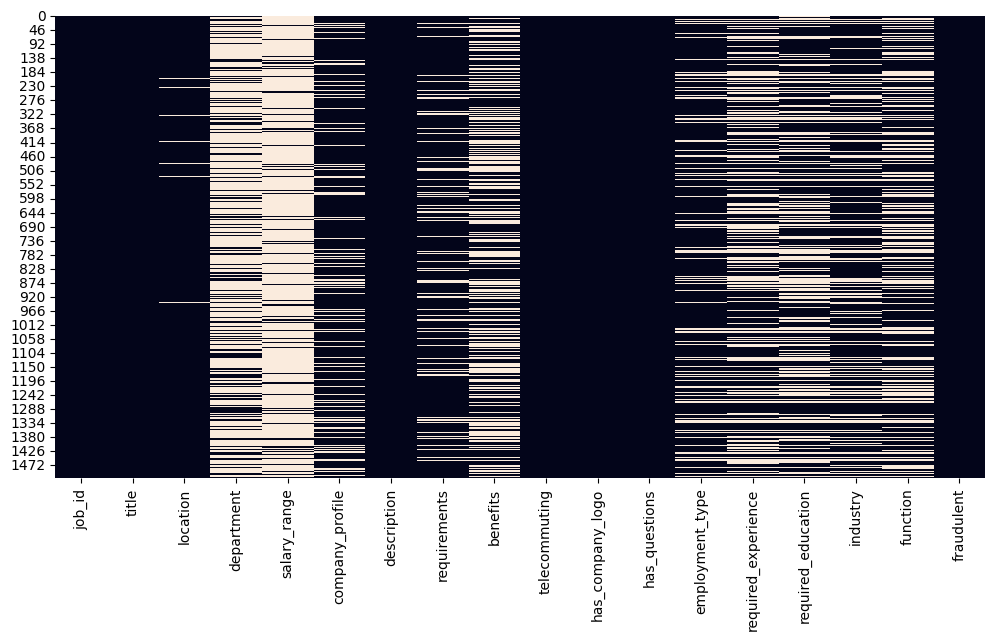

In [8]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(),cbar=False)
plt.show()

Step 5: Handle Missing Values

Fill text columns

In [9]:
text_columns=[
    'title',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

for col in text_columns:
    df[col]=df[col].fillna('')

Fill categorical columns

In [10]:
cat_columns=[
    'location',
    'department',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

for col in cat_columns:
    df[col]=df[col].fillna('Unknown')

Step 6: Check Target Distribution

In [11]:
df['fraudulent'].value_counts()

,count
fraudulent,
0,1480
1,34


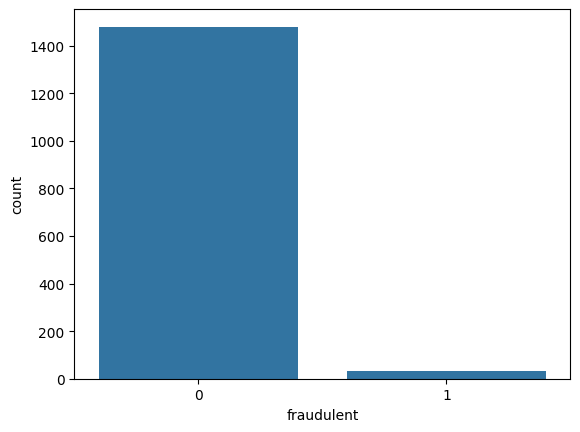

In [12]:
sns.countplot(x='fraudulent',data=df)
plt.show()

Analyze Categorical Features vs. Fraudulent

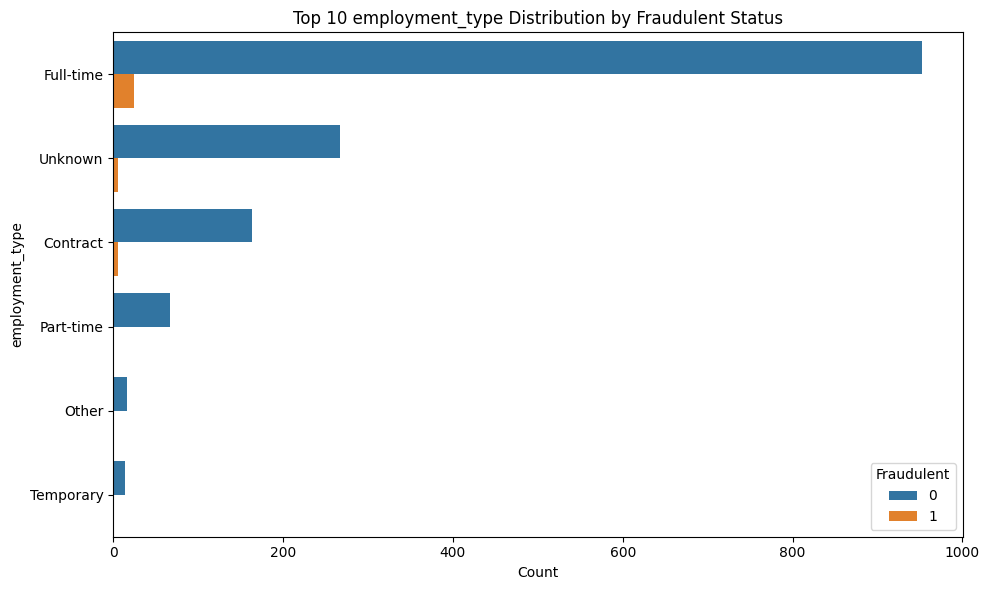

In [13]:
# Function to plot countplots for categorical features against 'fraudulent'
def plot_categorical_fraud(df, column):
    plt.figure(figsize=(10, 6))
    sns.countplot(y=column, hue='fraudulent', data=df, order=df[column].value_counts().index[:10])
    plt.title(f'Top 10 {column} Distribution by Fraudulent Status')
    plt.xlabel('Count')
    plt.ylabel(column)
    plt.legend(title='Fraudulent')
    plt.tight_layout()
    plt.show()

# Analyze 'employment_type'
plot_categorical_fraud(df, 'employment_type')


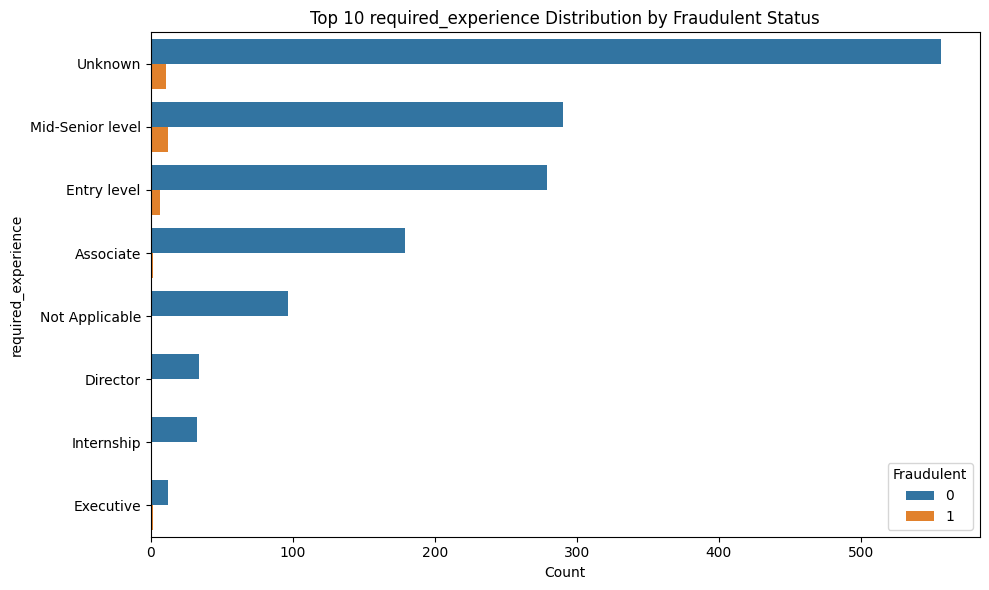

In [14]:
# Analyze 'required_experience'
plot_categorical_fraud(df, 'required_experience')

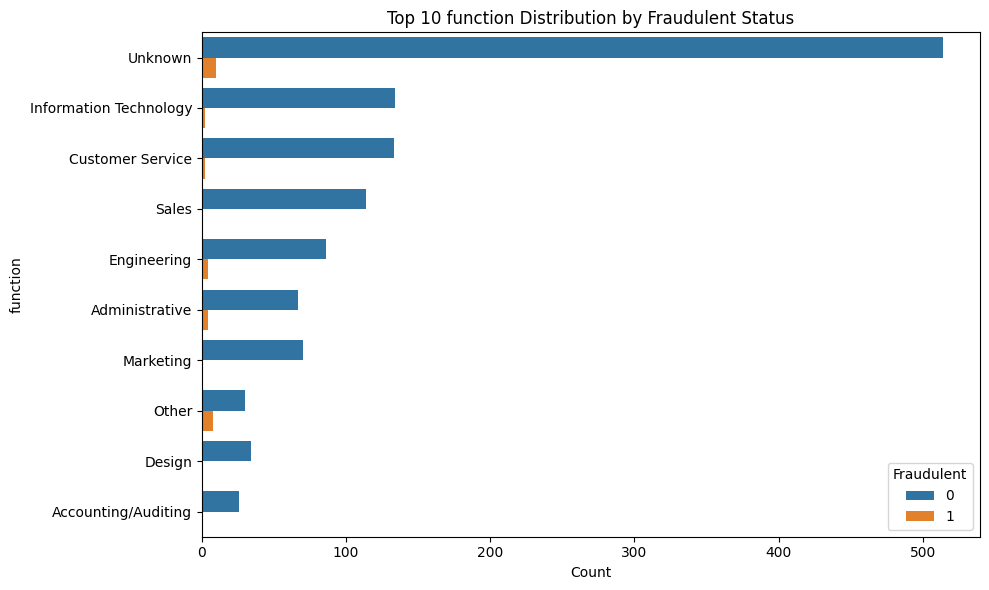

In [15]:
# Analyze 'function'
plot_categorical_fraud(df, 'function')

Step 7: Feature Engineering

Combine important text columns.

In [16]:
df['text']=(
    df['title']+" "+
    df['company_profile']+" "+
    df['description']+" "+
    df['requirements']+" "+
    df['benefits']
)

Step 8: Text Cleaning

In [17]:
import re
import string

def clean_text(text):

    text=text.lower()

    text=re.sub(r"http\S+"," ",text)

    text=re.sub(r"\d+"," ",text)

    text=text.translate(str.maketrans('','',string.punctuation))

    text=re.sub(r"\s+"," ",text)

    return text

In [18]:
df['clean_text']=df['text'].apply(clean_text)

Step 9: Remove Stopwords

In [19]:
import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words=set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [20]:
def remove_stopwords(text):

    return " ".join([word for word in text.split()
                     if word not in stop_words])

In [21]:
df['clean_text']=df['clean_text'].apply(remove_stopwords)

Step 10: TF-IDF Feature Extraction

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [23]:
vectorizer=TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2)
)

In [24]:
X_text=vectorizer.fit_transform(df['clean_text'])

In [25]:
y=df['fraudulent']

Step 11: Train Test Split

In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Step 12: Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression

lr=LogisticRegression(max_iter=1000)

lr.fit(X_train,y_train)

lr_pred=lr.predict(X_test)

Step 13: Naive Bayes

In [28]:
from sklearn.naive_bayes import MultinomialNB
nb=MultinomialNB()

nb.fit(X_train,y_train)
nb_pred=nb.predict(X_test)

Step 14: Random Forest

In [29]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [30]:
rf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [31]:
rf_pred=rf.predict(X_test)

Step 15: XGBoost

Install

In [32]:
!pip install xgboost

In [33]:
from xgboost import XGBClassifier
xgb=XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

In [34]:
xgb.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [35]:
xgb_pred=xgb.predict(X_test)

Step 16: Model Evaluation

In [36]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report

Create function

In [37]:
def evaluate(name,true,pred):

    print(name)

    print("Accuracy :",accuracy_score(true,pred))

    print("Precision:",precision_score(true,pred))

    print("Recall   :",recall_score(true,pred))

    print("F1 Score :",f1_score(true,pred))

    print(classification_report(true,pred))

In [38]:
evaluate("Logistic Regression",y_test,lr_pred)

Logistic Regression
Accuracy : 0.976897689768977
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       296
           1       0.00      0.00      0.00         7

    accuracy                           0.98       303
   macro avg       0.49      0.50      0.49       303
weighted avg       0.95      0.98      0.97       303



In [39]:
evaluate("Naive Bayes",y_test,nb_pred)

Naive Bayes
Accuracy : 0.966996699669967
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       296
           1       0.00      0.00      0.00         7

    accuracy                           0.97       303
   macro avg       0.49      0.49      0.49       303
weighted avg       0.95      0.97      0.96       303



In [40]:
evaluate("Random Forest",y_test,rf_pred)

Random Forest
Accuracy : 0.9867986798679867
Precision: 1.0
Recall   : 0.42857142857142855
F1 Score : 0.6
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       296
           1       1.00      0.43      0.60         7

    accuracy                           0.99       303
   macro avg       0.99      0.71      0.80       303
weighted avg       0.99      0.99      0.98       303



In [41]:
evaluate("XGBoost",y_test,xgb_pred)

XGBoost
Accuracy : 0.9801980198019802
Precision: 1.0
Recall   : 0.14285714285714285
F1 Score : 0.25
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       296
           1       1.00      0.14      0.25         7

    accuracy                           0.98       303
   macro avg       0.99      0.57      0.62       303
weighted avg       0.98      0.98      0.97       303



Step 17: Confusion Matrix

In [42]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,lr_pred)

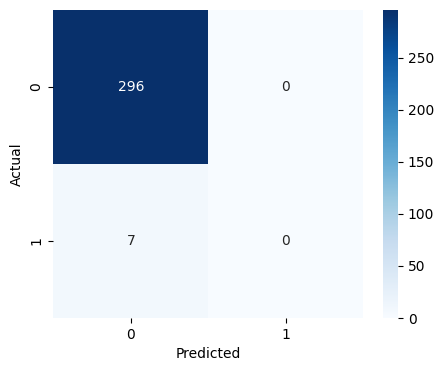

In [43]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

Step 18: ROC Curve

In [44]:
from sklearn.metrics import roc_curve,auc
prob=lr.predict_proba(X_test)[:,1]
fpr,tpr,_=roc_curve(y_test,prob)

roc_auc=auc(fpr,tpr)

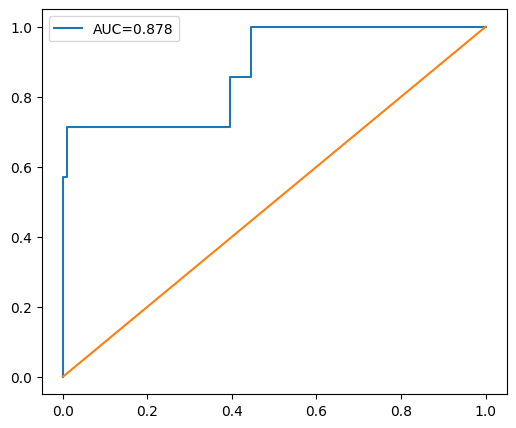

In [45]:
plt.figure(figsize=(6,5))

plt.plot(fpr,tpr,label="AUC="+str(round(roc_auc,3)))

plt.plot([0,1],[0,1])

plt.legend()

plt.show()

Step 19: Hyperparameter Tuning

In [46]:
from sklearn.model_selection import GridSearchCV
params={
    'C':[0.01,0.1,1,10]
}
grid=GridSearchCV(
    LogisticRegression(max_iter=1000),
    params,
    cv=5,
    scoring='f1'
)

In [47]:
grid.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.01, 0.1, 1, 10]}, scoring='f1')

In [48]:
grid.best_params_

{'C': 10}

Step 20: Compare Models

In [49]:
results=pd.DataFrame({

'Model':['Logistic Regression',
         'Naive Bayes',
         'Random Forest',
         'XGBoost'],

'Accuracy':[

accuracy_score(y_test,lr_pred),

accuracy_score(y_test,nb_pred),

accuracy_score(y_test,rf_pred),

accuracy_score(y_test,xgb_pred)

]

})

results

,Model,Accuracy
0,Logistic Regression,0.976898
1,Naive Bayes,0.966997
2,Random Forest,0.986799
3,XGBoost,0.980198


Visualization

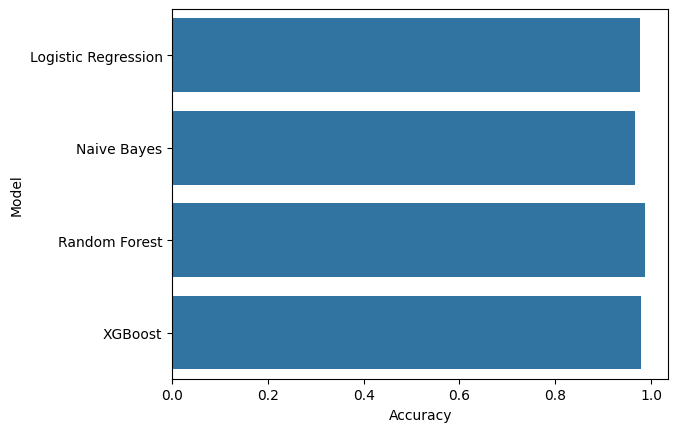

In [50]:
sns.barplot(
    x='Accuracy',
    y='Model',
    data=results
)

plt.show()

Step 21: Prediction System

In [51]:
def predict_job(title,
                company,
                description,
                requirements,
                benefits):

    text=title+" "+company+" "+description+" "+requirements+" "+benefits

    text=clean_text(text)

    text=remove_stopwords(text)

    vector=vectorizer.transform([text])

    pred=lr.predict(vector)[0]

    if pred==1:
        return "Fraudulent Job Posting"

    else:
        return "Real Job Posting"

Example

In [52]:
predict_job(
title="Software Engineer",

company="Google",

description="Develop AI products",

requirements="Python Machine Learning",

benefits="Health Insurance"
)

'Real Job Posting'

Step 22: Save Model

In [53]:
import joblib
joblib.dump(lr,'fake_job_detector.pkl')
joblib.dump(vectorizer,'tfidf.pkl')
model=joblib.load('fake_job_detector.pkl')

vectorizer=joblib.load('tfidf.pkl')